<center><h1>Zhang_Zhengshu_HW2</h1></center>
<br>
<br>

Name: Zhengshu Zhang
<br>
Github Username: forestzs
<br>
USC ID: 4664738582

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pandas.plotting import scatter_matrix
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

%matplotlib inline

Get the Cycle Power Plant Data Set

In [2]:
ccpp = pd.read_excel("data/CCPP/Folds5x2_pp.xlsx", sheet_name="Sheet1")
ccpp.head()

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


The data is the Combined Cycle Power Plant data set from the UCI Machine Learning Repository. A local copy of the workbook is read from `data/CCPP/Folds5x2_pp.xlsx`, so the notebook downloads nothing when it runs. The workbook holds five sheets that are shuffled versions of the same records. Footnote 1 of the assignment says to work with Sheet1, so Sheet1 is the only sheet read here.

### (b) Exploring the data

#### i. rows and columns

In [3]:
n_rows, n_cols = ccpp.shape
print("rows:", n_rows)
print("columns:", n_cols)
print("column names:", list(ccpp.columns))
print("missing values:", int(ccpp.isna().sum().sum()))

rows: 9568
columns: 5
column names: ['AT', 'V', 'AP', 'RH', 'PE']
missing values: 0


The data set has 9568 rows and 5 columns. Each row is one hourly average observation of the plant while it was running at full load, taken over the six years 2006 to 2011. The four predictor columns are the ambient conditions measured in that hour. AT is the ambient temperature, V is the exhaust vacuum, AP is the ambient pressure and RH is the relative humidity. The fifth column is PE, the net hourly electrical energy output of the plant, and PE is the response predicted from the other four.

#### ii. pairwise scatterplots of all the varianbles

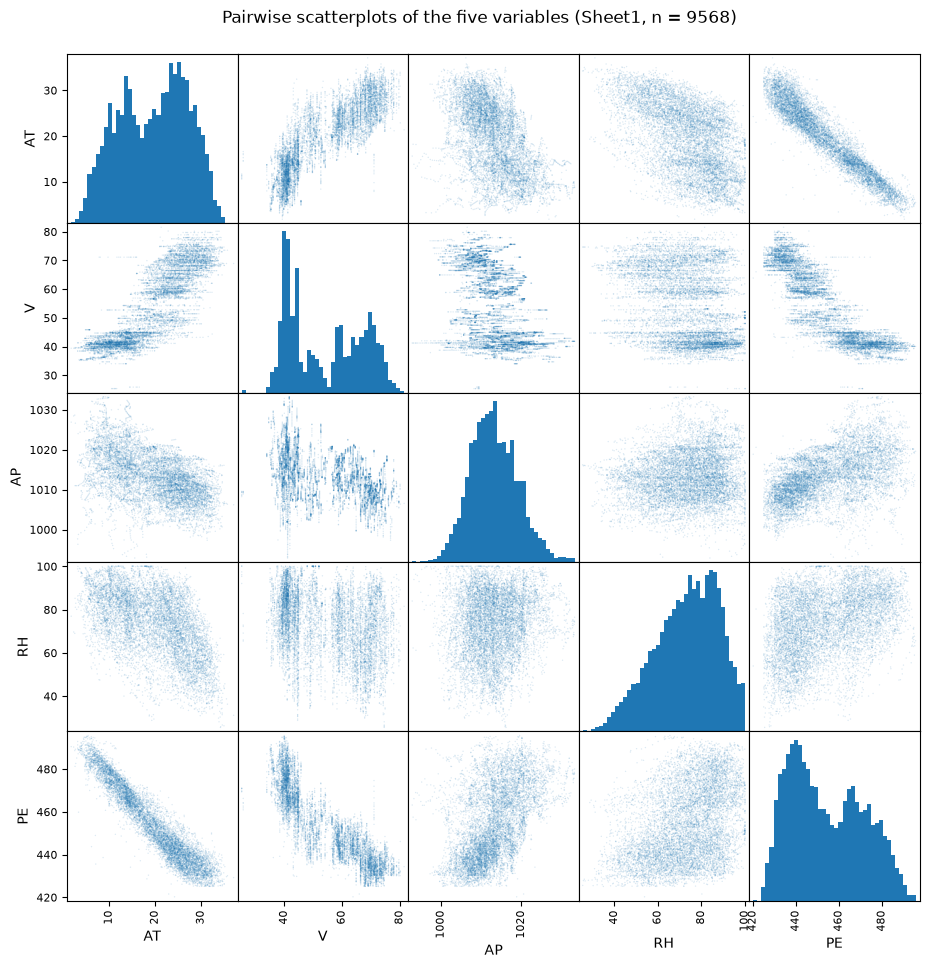

In [4]:
scatter_matrix(ccpp, figsize=(11, 11), diagonal="hist", s=4, alpha=0.15,
               hist_kwds={"bins": 40})
plt.suptitle("Pairwise scatterplots of the five variables (Sheet1, n = 9568)", y=0.92)
plt.show()

In [5]:
ccpp.corr().round(3)

,AT,V,AP,RH,PE
AT,1.000,0.844,-0.508,-0.543,-0.948
V,0.844,1.000,-0.414,-0.312,-0.870
AP,-0.508,-0.414,1.000,0.100,0.518
RH,-0.543,-0.312,0.100,1.000,0.390
PE,-0.948,-0.870,0.518,0.390,1.000


Each panel uses marker size 4 and alpha 0.15, which keeps the 9568 points from merging into a solid block so that the density of the cloud stays readable.

AT and V both have a strong negative relation with the response. Output falls as ambient temperature or exhaust vacuum rises, and the PE against AT panel is much the tightest band in the matrix. AT correlates -0.948 with PE, and V correlates -0.870. AP has a moderate positive relation with PE, and RH only a weak one, with correlations of 0.518 and 0.390. The AP and RH panels are both wide enough that neither predictor would pin down PE on its own.

The predictors are also strongly related to each other, which matters for the multiple regression later. AT and V move together with a correlation of 0.844, AT is moderately negatively related to AP at -0.508 and to RH at -0.543, and AP and RH are almost unrelated at 0.100.

Two of the relations look bent rather than straight. The PE against AT band is straight through the middle of the temperature range, but it flattens at both the coldest and the warmest hours. The PE against V panel is not one band at all but two clouds, a dense low vacuum group and a second group above roughly 50. Mean output is also not highest at the very lowest vacuum readings. Output rises as vacuum falls, but that rise stops at about 35 and reverses over the last few readings. PE against RH looks straight and simply weak. The diagonal histograms show that V, AT and PE are each bimodal, which is what produces the clustering in the panels that involve them.

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [6]:
q1 = ccpp.quantile(0.25)
q3 = ccpp.quantile(0.75)
summary = pd.DataFrame({
    "Mean": ccpp.mean(),
    "Median": ccpp.median(),
    "Range": ccpp.max() - ccpp.min(),
    "First quartile": q1,
    "Third quartile": q3,
    "Interquartile range": q3 - q1,
})
summary.round(4)

,Mean,Median,Range,First quartile,Third quartile,Interquartile range
AT,19.6512,20.345,35.30,13.5100,25.72,12.2100
V,54.3058,52.080,56.20,41.7400,66.54,24.8000
AP,1013.2591,1012.940,40.41,1009.1000,1017.26,8.1600
RH,73.3090,74.975,74.60,63.3275,84.83,21.5025
PE,454.3650,451.550,75.50,439.7500,468.43,28.6800


Range is reported as a single number, the maximum minus the minimum, rather than as a pair of endpoints. The interquartile range is likewise a single number, Q3 minus Q1. The same convention is used for all five variables. Neither range nor interquartile range comes out of the standard summary, so both are computed here from the column extremes and the quartiles.

The mean and the median are close for every variable, so none of the five is heavily skewed. The mean of RH does sit about 1.7 below its median, which reflects a longer tail towards dry hours.

The summary also shows how differently the five columns are scaled. AP spans about 40 millibar around 1013 while AT spans about 35 degrees around 19.7. That difference in scale is why the KNN part of this homework will need the features normalised.

### (c) Simple Linear Regression

In [7]:
preds = ["AT", "V", "AP", "RH"]
simple_fits = {}
rows = []
for p in preds:
    fit = sm.OLS(ccpp["PE"], sm.add_constant(ccpp[p])).fit()
    simple_fits[p] = fit
    rows.append([p, fit.params[p], fit.params["const"], fit.bse[p],
                 fit.tvalues[p], fit.pvalues[p], fit.rsquared])

simple_table = pd.DataFrame(
    rows,
    columns=["Predictor", "Slope", "Intercept", "Std. error of slope",
             "t statistic", "p value", "R squared"])
simple_table

,Predictor,Slope,Intercept,Std. error of slope,t statistic,p value,R squared
0,AT,-2.171320,497.034120,0.007443,-291.715195,0.0,0.898948
1,V,-1.168135,517.801526,0.006776,-172.401540,0.0,0.756518
2,AP,1.489872,-1055.260989,0.025126,59.296232,0.0,0.268769
3,RH,0.455650,420.961766,0.011006,41.398730,0.0,0.151939


In [8]:
for p in preds:
    print(simple_fits[p].summary())
    print()

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Sat, 19 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:01:42   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        497.0341      0.156   3177.280      0.0

All four simple regressions show a statistically significant association between the predictor and the response at the 5 per cent significance level. The p value of each simple regression's slope is too small to print as a number and shows as 0.0, so all four sit far below that threshold. The weakest association is RH, at a t statistic of 41.4 on 9566 degrees of freedom.

Significance is not informative on its own here, because with n = 9568 even a negligible effect would clear any conventional threshold. The slopes and the R squared values are the more useful comparison. AT alone explains 89.9 per cent of the variance in PE, with output falling about 2.17 MW for each additional degree. V explains 75.7 per cent, at about 1.17 MW per unit of vacuum. AP explains only 26.9 per cent and RH only 15.2 per cent, so despite their tiny p values those two leave most of the variation in PE unaccounted for. Judged by fit rather than by significance, AT is close to sufficient on its own, V is a useful second, and AP and RH are weak single predictors.

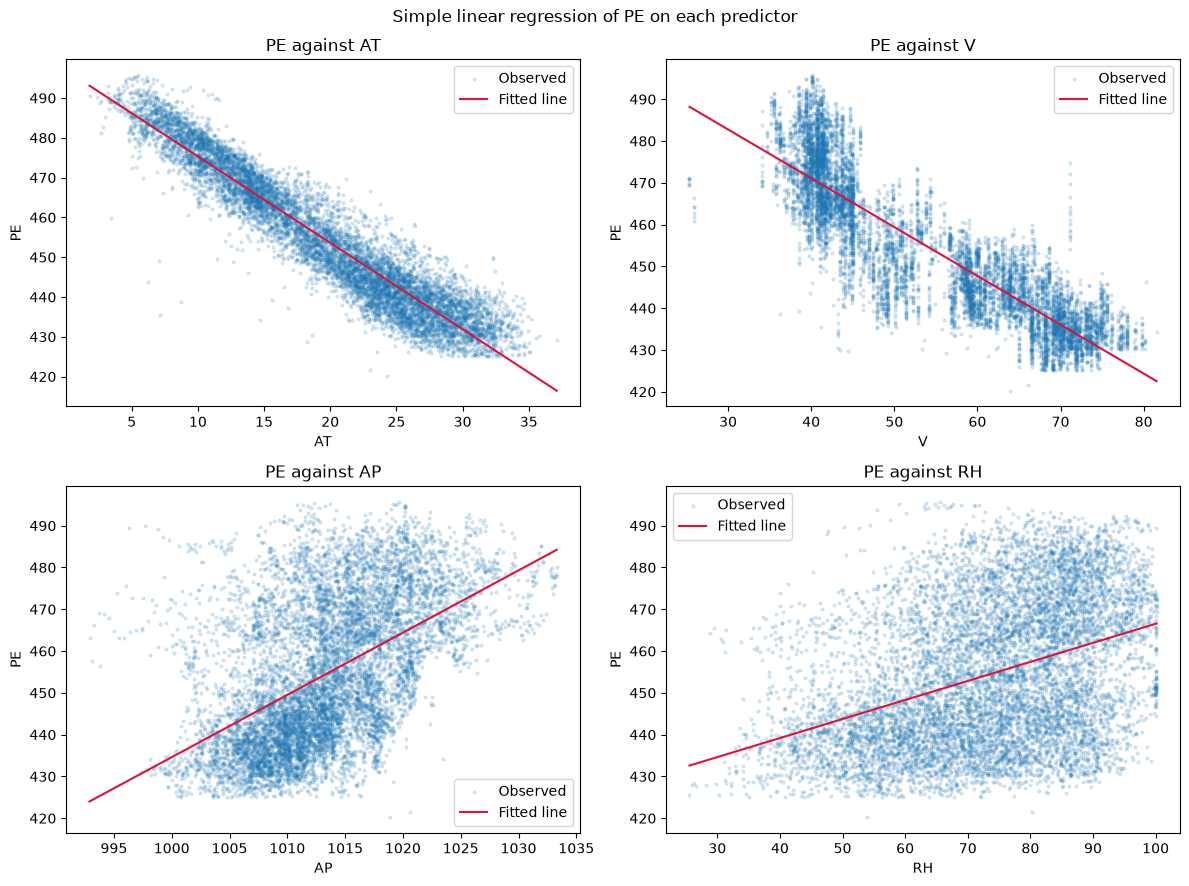

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, p in zip(axes.ravel(), preds):
    fit = simple_fits[p]
    grid = np.linspace(ccpp[p].min(), ccpp[p].max(), 100)
    ax.scatter(ccpp[p], ccpp["PE"], s=4, alpha=0.15, label="Observed")
    ax.plot(grid, fit.params["const"] + fit.params[p] * grid,
            color="crimson", label="Fitted line")
    ax.set_title("PE against " + p)
    ax.set_xlabel(p)
    ax.set_ylabel("PE")
    ax.legend()

fig.suptitle("Simple linear regression of PE on each predictor")
fig.tight_layout()
plt.show()

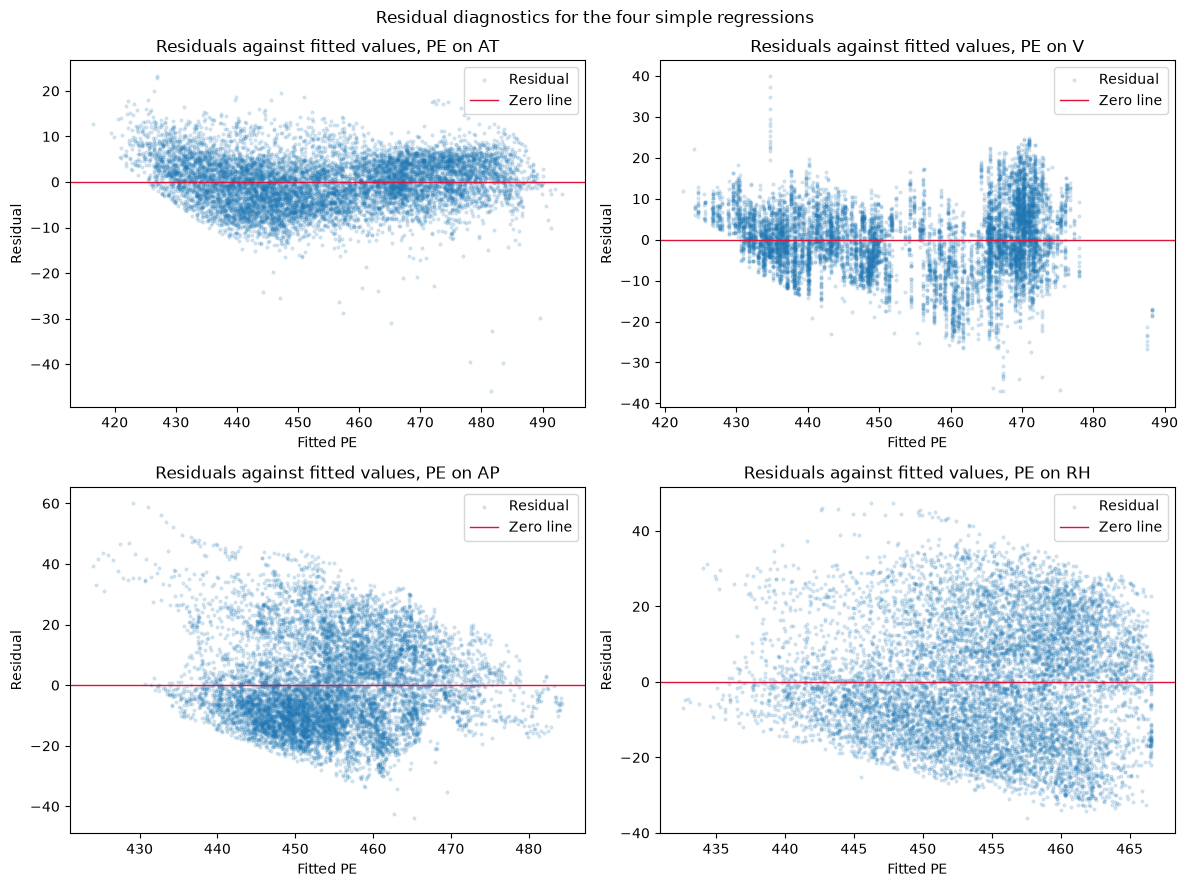

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, p in zip(axes.ravel(), preds):
    fit = simple_fits[p]
    ax.scatter(fit.fittedvalues, fit.resid, s=4, alpha=0.15, label="Residual")
    ax.axhline(0, color="crimson", lw=1, label="Zero line")
    ax.set_title("Residuals against fitted values, PE on " + p)
    ax.set_xlabel("Fitted PE")
    ax.set_ylabel("Residual")
    ax.legend()

fig.suptitle("Residual diagnostics for the four simple regressions")
fig.tight_layout()
plt.show()

The fitted lines and the residual plots back up the table. PE against AT is a narrow band that the line follows closely, and its residual plot is the flattest and narrowest of the four. PE against V splits into two clouds that a single line can only average over, so its residuals fall into visible blocks instead of one even band. The AP and RH panels show lines drawn through clouds so wide that the residuals are barely smaller than the spread of PE itself. The residual standard deviation is still about 86 per cent of the standard deviation of PE for AP, and about 92 per cent for RH. Residuals nearly as wide as the spread of PE itself are what a low R squared looks like on the page.

In [11]:
cook_cut = 4 / n_rows
lev_cut = 3 * 2 / n_rows
rows = []
for p in preds:
    infl = simple_fits[p].get_influence()
    cook = infl.cooks_distance[0]
    rows.append([p,
                 int((np.abs(infl.resid_studentized_external) > 3).sum()),
                 int((cook > cook_cut).sum()),
                 int((infl.hat_matrix_diag > lev_cut).sum()),
                 cook.max()])

outliers = pd.DataFrame(
    rows,
    columns=["Predictor", "|studentised residual| > 3", "Cook's D > 4/n",
             "leverage > 3p/n", "Largest Cook's D"])
print("Cook's D cutoff 4/n =", round(cook_cut, 8))
print("leverage cutoff 3p/n =", round(lev_cut, 8))
outliers

Cook's D cutoff 4/n = 0.00041806
leverage cutoff 3p/n = 0.00062709


,Predictor,|studentised residual| > 3,Cook's D > 4/n,leverage > 3p/n,Largest Cook's D
0,AT,42,416,7,0.014325
1,V,33,423,13,0.003243
2,AP,30,300,239,0.008152
3,RH,2,249,173,0.002059


Outlier candidates were flagged by three rules, applied to each simple regression separately. The first flags any point whose residual is more than three standard deviations from the fitted line. The second uses Cook's distance, which measures how far the fitted line would move if that one point were dropped, and flags anything above the usual cutoff of 4/n = 0.00041806. The third uses leverage, which measures how unusual a point's predictor value is, and flags anything above three times the average leverage, 6/9568 = 0.00062709.

The three rules disagree sharply about how many points are suspect. The residual rule flags 42, 33, 30 and 2 points for AT, V, AP and RH. The much looser Cook's distance rule flags 416, 423, 300 and 249. The leverage rule flags 7, 13, 239 and 173.

I would not remove any of the flagged points. The largest Cook's distance anywhere in the four fits is 0.0143, far below the level at which a single observation could meaningfully move a fit built from 9568 points. The flagged points are hourly readings from a real plant with no sign of being recording errors, so the flags mark ordinary tail behaviour rather than bad data. Dropping several hundred points per model would also mean fitting only the bulk of the cloud, which would understate the genuine spread of plant output. No rows are removed from the data set, and every later part of this homework works on the full 9568 rows.

### (d) Multiple Regression

In [12]:
multi = sm.OLS(ccpp["PE"], sm.add_constant(ccpp[preds])).fit()
print(multi.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Sat, 19 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:02:19   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.0

In [13]:
multi_table = pd.DataFrame({
    "Coefficient": multi.params,
    "Std. error": multi.bse,
    "t statistic": multi.tvalues,
    "p value": multi.pvalues,
})
multi_table

,Coefficient,Std. error,t statistic,p value
const,454.609274,9.748512,46.633709,0.000000e+00
AT,-1.977513,0.015289,-129.342024,0.000000e+00
V,-0.233916,0.007282,-32.122109,4.375305e-215
AP,0.062083,0.009458,6.564086,5.507109e-11
RH,-0.158054,0.004168,-37.918473,3.104584e-293


Every one of the four predictors is significant at the 5 per cent level, so the null hypothesis H0: beta_j = 0 is rejected for AT, V, AP and RH alike.

In this four-predictor fit only AT's p value is too small to print as a number and shows as 0.0, while in part (c) all four did, so that figure should not be read as a literal zero. V and RH print as 4.4e-215 and 3.1e-293, and AP is the weakest of the four at 5.5e-11 on a t statistic of 6.56.

The signs say that output falls as ambient temperature, exhaust vacuum or relative humidity rises, and climbs slightly with ambient pressure. The sizes of the four coefficients are very uneven. Holding the others fixed, a one degree rise in AT costs 1.978 MW, a one unit rise in V costs 0.234 MW, a one unit rise in RH costs 0.158 MW, and a one millibar rise in AP buys only 0.062 MW. Together the four explain 92.9 per cent of the variance in PE, against the 89.9 per cent that AT reaches on its own, so the other three add about three percentage points of explained variance beyond temperature.

### (e) 1c Compare to 1d

In [14]:
compare = pd.DataFrame({
    "Simple (c)": [simple_fits[p].params[p] for p in preds],
    "Multiple (d)": [multi.params[p] for p in preds],
}, index=preds)
compare["Change"] = compare["Multiple (d)"] - compare["Simple (c)"]
print("standard deviations:", ccpp[preds].std().round(4).to_dict())
compare

standard deviations: {'AT': 7.4525, 'V': 12.7079, 'AP': 5.9388, 'RH': 14.6003}


,Simple (c),Multiple (d),Change
AT,-2.171320,-1.977513,0.193807
V,-1.168135,-0.233916,0.934219
AP,1.489872,0.062083,-1.427789
RH,0.455650,-0.158054,-0.613704


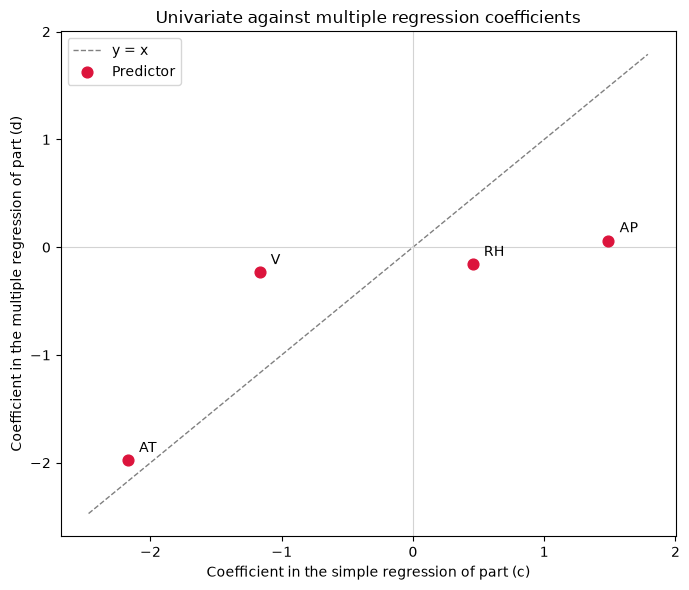

In [15]:
fig, ax = plt.subplots(figsize=(7, 6))
lo = min(compare["Simple (c)"].min(), compare["Multiple (d)"].min()) - 0.3
hi = max(compare["Simple (c)"].max(), compare["Multiple (d)"].max()) + 0.3
ax.plot([lo, hi], [lo, hi], color="grey", ls="--", lw=1, label="y = x")
ax.axhline(0, color="lightgrey", lw=0.8)
ax.axvline(0, color="lightgrey", lw=0.8)
ax.scatter(compare["Simple (c)"], compare["Multiple (d)"], s=60, color="crimson",
           zorder=3, label="Predictor")
for p in preds:
    ax.annotate(p, (compare.loc[p, "Simple (c)"], compare.loc[p, "Multiple (d)"]),
                textcoords="offset points", xytext=(8, 6))
ax.set_title("Univariate against multiple regression coefficients")
ax.set_xlabel("Coefficient in the simple regression of part (c)")
ax.set_ylabel("Coefficient in the multiple regression of part (d)")
ax.legend()
fig.tight_layout()
plt.show()

The figure puts each predictor's simple coefficient from part (c) on the horizontal axis and its multiple coefficient from part (d) on the vertical. A predictor whose two coefficients agree would sit on the dashed line y = x. Only AT sits close to that line. Its coefficient moves from -2.171 to -1.978, a shift of about nine per cent. The other three move a long way. V goes from -1.168 to -0.234, keeping its sign but losing four fifths of its size. AP goes from 1.490 to 0.062, almost to nothing. RH changes sign, from 0.456 in the simple fit to -0.158 in the multiple fit.

The large shifts in V, AP and RH happen because a univariate coefficient absorbs the effect of every other predictor correlated with it, while a multiple-regression coefficient is the effect of that predictor with the other three held fixed. AT is the dominant driver of PE. Each of the other three predictors therefore inherits part of AT's effect in its own simple fit, in proportion to how strongly that predictor is correlated with AT. V is correlated 0.844 with AT, AP is correlated -0.508 and RH -0.543, and the coefficients of those three are exactly the ones that collapse. AT itself has no larger confounder to borrow from, which is why it barely moves.

RH is the predictor that changes sign, and the reason is worth spelling out. Its simple slope is positive, 0.456, which says that humid hours tend to be high-output hours. But RH is correlated -0.543 with AT, so humid hours are mostly cold hours, and cold hours have high output because AT drives PE down. The simple fit cannot separate the two effects, so it credits the temperature effect to humidity.

Once AT, V and AP are in the model and temperature is held fixed, the remaining effect of humidity is negative, -0.158. At a given temperature, pressure and vacuum, more humid air produces slightly less power. The positive simple slope reflected temperature rather than any humidity effect.

A rough check supports that reading. Part of RH's simple slope is really AT's effect arriving through the correlation between RH and AT. That part is the correlation of -0.543, times the ratio of the standard deviations of AT and RH, 7.4525 over 14.6003, times AT's multiple coefficient of -1.9775. Multiplying the three gives -0.543 * (7.4525 / 14.6003) * -1.9775 = 0.548. Taking 0.548 away from the simple slope of 0.456 leaves -0.092, which is negative, like the fitted -0.158.

### (f) Nonlinear Association

In [16]:
# AP is around 1013, so its square and cube are enormous next to the other terms.
# Fitting on the raw powers is unreliable, so each cubic is fitted in the
# standardised predictor z = (X - mean) / sd instead.
cubic_fits = {}
rows = []
for p in preds:
    x = ccpp[p]
    z = (x - x.mean()) / x.std()
    basis = pd.DataFrame({"z": z, "z^2": z ** 2, "z^3": z ** 3})
    fit = sm.OLS(ccpp["PE"], sm.add_constant(basis)).fit()
    cubic_fits[p] = fit
    for term in ["z", "z^2", "z^3"]:
        rows.append([p, term, fit.params[term], fit.tvalues[term], fit.pvalues[term],
                     fit.rsquared, simple_fits[p].rsquared])

cubic_table = pd.DataFrame(
    rows,
    columns=["Predictor", "Term", "Coefficient", "t statistic", "p value",
             "R squared cubic", "R squared linear"])
ap = ccpp["AP"]
print("correlation of AP with AP squared:", round(ap.corr(ap ** 2), 8))
print("correlation of AP with AP cubed: ", round(ap.corr(ap ** 3), 8))
cubic_table

correlation of AP with AP squared: 0.99999133
correlation of AP with AP cubed:  0.99996529


,Predictor,Term,Coefficient,t statistic,p value,R squared cubic,R squared linear
0,AT,z,-18.107530,-167.159764,0.000000e+00,0.911883,0.898948
1,AT,z^2,1.808041,33.381378,3.311808e-231,0.911883,0.898948
2,AT,z^3,1.107136,22.594188,3.652185e-110,0.911883,0.898948
3,V,z,-15.888133,-85.721661,0.000000e+00,0.775022,0.756518
4,V,z^2,3.096876,24.714193,8.977010e-131,0.775022,0.756518
5,V,z^3,0.275728,2.464579,1.373489e-02,0.775022,0.756518
6,AP,z,11.667710,50.666518,0.000000e+00,0.297543,0.268769
7,AP,z^2,1.560244,14.377009,2.192722e-46,0.297543,0.268769
8,AP,z^3,-1.045428,-17.483547,2.123338e-67,0.297543,0.268769
9,RH,z,7.740764,26.718657,9.648727e-152,0.153743,0.151939


In [17]:
nonlinear = []
for p in preds:
    fit = cubic_fits[p]
    joint = fit.f_test("z^2 = 0, z^3 = 0")
    x = ccpp[p]
    grid = np.linspace(x.min(), x.max(), 400)
    gz = (grid - x.mean()) / x.std()
    curve = (fit.params["const"] + fit.params["z"] * gz
             + fit.params["z^2"] * gz ** 2 + fit.params["z^3"] * gz ** 3)
    line = simple_fits[p]
    straight = line.params["const"] + line.params[p] * grid
    nonlinear.append([p, fit.rsquared - line.rsquared, float(joint.fvalue),
                      float(joint.pvalue), np.abs(curve - straight).max()])

nonlinear_table = pd.DataFrame(
    nonlinear,
    columns=["Predictor", "Gain in R squared", "Joint F for the two curved terms",
             "p value", "Largest gap from the straight line (MW)"])
nonlinear_table

,Predictor,Gain in R squared,Joint F for the two curved terms,p value,Largest gap from the straight line (MW)
0,AT,0.012935,701.967278,3.478379e-285,17.988764
1,V,0.018504,393.314147,7.040304e-165,12.034803
2,AP,0.028775,195.885627,4.209145e-84,49.581546
3,RH,0.001803,10.188863,3.799622e-05,10.066250


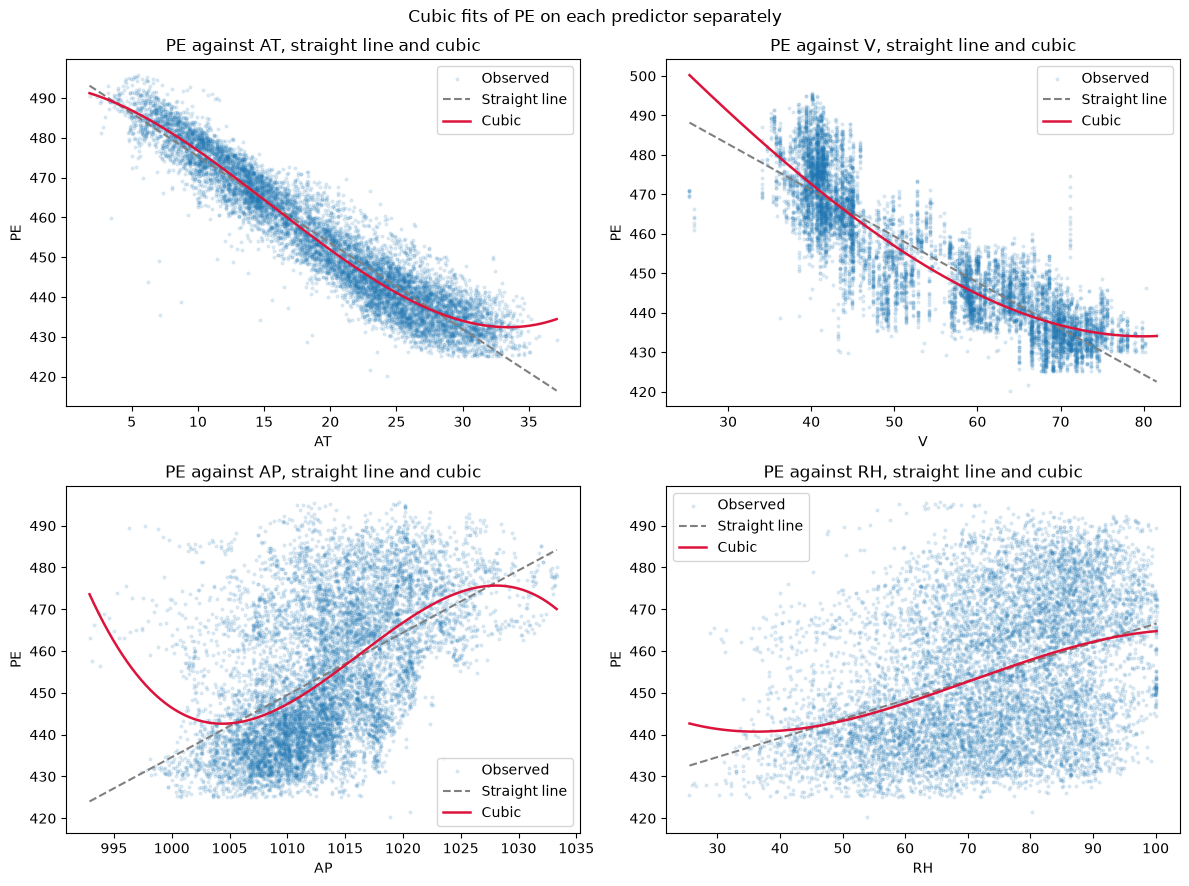

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, p in zip(axes.ravel(), preds):
    x = ccpp[p]
    grid = np.linspace(x.min(), x.max(), 400)
    gz = (grid - x.mean()) / x.std()
    fit = cubic_fits[p]
    line = simple_fits[p]
    ax.scatter(x, ccpp["PE"], s=4, alpha=0.12, label="Observed")
    ax.plot(grid, line.params["const"] + line.params[p] * grid,
            color="grey", ls="--", lw=1.5, label="Straight line")
    ax.plot(grid, fit.params["const"] + fit.params["z"] * gz
            + fit.params["z^2"] * gz ** 2 + fit.params["z^3"] * gz ** 3,
            color="crimson", lw=1.8, label="Cubic")
    ax.set_title("PE against " + p + ", straight line and cubic")
    ax.set_xlabel(p)
    ax.set_ylabel("PE")
    ax.legend()

fig.suptitle("Cubic fits of PE on each predictor separately")
fig.tight_layout()
plt.show()

Taking 5 per cent as the level throughout, there is evidence of nonlinear association for all four predictors, though it is not equally convincing in each case. For AT the quadratic and cubic terms are both strongly significant, at t = 33.4 and 22.6. For V both are significant, although the cubic only marginally so, at t = 24.7 and 2.46 with p = 0.014. For AP both are significant, at t = 14.4 and -17.5.

For RH the picture is mixed. The quadratic term is not significant at 5 per cent (t = -1.64, p = 0.101) while the cubic term is (t = -4.34, p = 1.4e-05), and the joint F test of the two curved terms together is significant at F = 10.2. So if any one significant curved term counts as evidence, every predictor shows some curvature, and RH shows the least of it.

AP is around 1013, so AP squared and AP cubed are enormous next to the other terms and each is correlated above 0.9999 with AP itself. A fit on those raw powers cannot tell the three apart, so their separate coefficients would mean little. Standardising each predictor first, as z = (X - mean) / sd, brings those correlations far down and avoids the problem. The coefficient column above is therefore on the standardised scale, so each entry reads as the effect of a one standard deviation move in the predictor.

A significant term is not the same as a large effect. With n = 9568 the curved terms are easy to detect even when they bend the fit very little, so their size matters more than their p values. Adding the two curved terms raises R squared by 0.0288 for AP, 0.0185 for V and 0.0129 for AT, but by only 0.0018 for RH, a negligible improvement on an already weak fit.

The largest gap between the cubic and the straight line over the observed range is 49.6 MW for AP, 18.0 MW for AT, 12.0 MW for V and 10.1 MW for RH. In every case that maximum falls at the very edge of the range, where the data thin out and a cubic is free to swing. Through the body of the data the two curves stay close, as the figure shows. So AT, V and AP have real but modest curvature, and RH's nonlinearity is statistically detectable and practically irrelevant.

### (g) Interactions of Predictors

In [19]:
pairs = [(a, b) for i, a in enumerate(preds) for b in preds[i + 1:]]

def with_interactions(frame, center=False):
    base = frame[preds]
    if center:
        base = base - base.mean()
    out = base.copy()
    for a, b in pairs:
        out[f"{a}:{b}"] = base[a] * base[b]
    return out

print("pairwise interaction terms:", [f"{a}:{b}" for a, b in pairs])
inter = sm.OLS(ccpp["PE"], sm.add_constant(with_interactions(ccpp))).fit()
print(inter.summary())

pairwise interaction terms: ['AT:V', 'AT:AP', 'AT:RH', 'V:AP', 'V:RH', 'AP:RH']
                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Sat, 19 Sep 2026   Prob (F-statistic):               0.00
Time:                        14:02:20   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------

In [20]:
inter_table = pd.DataFrame({
    "Coefficient": inter.params,
    "Std. error": inter.bse,
    "t statistic": inter.tvalues,
    "p value": inter.pvalues,
})
inter_table["Significant at 0.05"] = np.where(inter.pvalues < 0.05, "yes", "no")
inter_table

,Coefficient,Std. error,t statistic,p value,Significant at 0.05
const,685.782468,78.640060,8.720523,3.231607e-18,yes
AT,-4.347014,2.373139,-1.831757,6.701873e-02,no
V,-7.674858,1.350761,-5.681879,1.371251e-08,yes
AP,-0.152355,0.076817,-1.983346,4.735732e-02,yes
RH,1.570907,0.773350,2.031301,4.225213e-02,yes
AT:V,0.020971,0.000899,23.337763,3.333358e-117,yes
AT:AP,0.001759,0.002339,0.752031,4.520509e-01,no
AT:RH,-0.005230,0.000812,-6.444357,1.216944e-10,yes
V:AP,0.006812,0.001327,5.135000,2.877026e-07,yes
V:RH,0.000839,0.000489,1.716004,8.619366e-02,no


In [21]:
inter_c = sm.OLS(ccpp["PE"],
                 sm.add_constant(with_interactions(ccpp, center=True))).fit()
main_effects = pd.DataFrame({
    "(d) no interactions": [multi.params[p] for p in preds],
    "(g) raw products": [inter.params[p] for p in preds],
    "(g) centred products": [inter_c.params[p] for p in preds],
}, index=preds)
print("R squared, raw", round(inter.rsquared, 8),
      " centred", round(inter_c.rsquared, 8),
      " part (d)", round(multi.rsquared, 8))
main_effects

R squared, raw 0.93630575  centred 0.93630575  part (d) 0.92869609


,(d) no interactions,(g) raw products,(g) centred products
AT,-1.977513,-4.347014,-1.809235
V,-0.233916,-7.674858,-0.298594
AP,0.062083,-0.152355,0.134004
RH,-0.158054,1.570907,-0.119503


Four of the six pairwise interactions are significant at the 5 per cent level. They are the AT and V term, which the table lists as AT:V, at t = 23.3, the AT and RH term at t = -6.44, the V and AP term at t = 5.14, and the AP and RH term at t = -2.13 with p = 0.034. The two that are not significant are the AT and AP term, at p = 0.452, and the V and RH term, at p = 0.086. At a 1 per cent level the AP and RH term would drop out as well, leaving the AT and V, the AT and RH, and the V and AP terms.

So there is evidence that interactions are associated with the response, and that evidence is concentrated in the AT and V term, much the strongest of the six. The strength of that term matches the 0.844 correlation between AT and V. Adding the six products raises R squared from 0.928696 in part (d) to 0.936306.

The main effects do change, and the comparison needs care. With raw products, each main effect becomes the slope at the point where the other three predictors are all zero. For AP that means zero millibar, far outside the data. Read that way, AT appears insignificant at p = 0.067, and AP and RH flip sign, which is an artefact of reading the model at an impossible point rather than a finding.

Centring the predictors before forming the products repairs the interpretation without changing the model at all. R squared is 0.936306 either way, and every interaction coefficient, standard error and p value is identical, so the centred main effects below come from the same fit rather than from a different model. What changes is that each main effect becomes the slope at the mean of the other predictors. On that scale the main effects are close to their part (d) values without being equal to them. AT moves from -1.978 to -1.809, V from -0.234 to -0.299, AP from 0.062 to 0.134 and RH from -0.158 to -0.120. So the interactions absorb some of what the main effects carried in part (d), most visibly for AP, whose coefficient roughly doubles once the products are present.

### (h) Improvement

In [22]:
SEED = 42
rng = np.random.default_rng(SEED)
order = rng.permutation(len(ccpp))
n_train = int(round(0.7 * len(ccpp)))
train = ccpp.iloc[np.sort(order[:n_train])]
test = ccpp.iloc[np.sort(order[n_train:])]
print("seed:", SEED)
print("training rows:", len(train), " test rows:", len(test))
print(f"split: {len(train) / len(ccpp):.1%} / {len(test) / len(ccpp):.1%}")

seed: 42
training rows: 6698  test rows: 2870
split: 70.0% / 30.0%


In [23]:
def mse(y, pred):
    return float(((y - pred) ** 2).mean())

model1 = sm.OLS(train["PE"], sm.add_constant(train[preds])).fit()
pred1_train = model1.fittedvalues
pred1_test = model1.predict(sm.add_constant(test[preds]))
model1.params

const    469.167879
AT        -1.991015
V         -0.230320
AP         0.047897
RH        -0.159222
dtype: float64

In [24]:
# Centred on the training means only, so the test rows play no part in building the
# design. Centring also keeps the main effects interpretable, as in part (g).
means = train[preds].mean()

def full_design(frame):
    base = frame[preds] - means
    out = pd.DataFrame(index=frame.index)
    for p in preds:
        out[p] = base[p]
    for a, b in pairs:
        out[f"{a}:{b}"] = base[a] * base[b]
    for p in preds:
        out[f"{p}^2"] = base[p] ** 2
    return out

design_train = full_design(train)
design_test = full_design(test)
print("terms in the full model:", len(design_train.columns))
print(list(design_train.columns))

terms in the full model: 14
['AT', 'V', 'AP', 'RH', 'AT:V', 'AT:AP', 'AT:RH', 'V:AP', 'V:RH', 'AP:RH', 'AT^2', 'V^2', 'AP^2', 'RH^2']


In [25]:
def parents(term):
    if ":" in term:
        return set(term.split(":"))
    if term.endswith("^2"):
        return {term[:-2]}
    return {term}

ALPHA = 0.05
kept = list(design_train.columns)
dropped = []
while True:
    step = sm.OLS(train["PE"], sm.add_constant(design_train[kept])).fit()
    higher = [t for t in kept if ":" in t or t.endswith("^2")]
    protected = set().union(*[parents(t) for t in higher]) if higher else set()
    removable = [t for t in kept
                 if (":" in t or t.endswith("^2")) or t not in protected]
    worst = max(removable, key=lambda t: step.pvalues[t])
    if step.pvalues[worst] <= ALPHA:
        break
    dropped.append((worst, step.pvalues[worst]))
    kept.remove(worst)

print("dropped, in order:")
for term, pval in dropped:
    print(f"  {term:8s} p = {pval:.4f}")
print("kept:", kept)

dropped, in order:
  AT:AP    p = 0.7845
  V:RH     p = 0.4458
  V^2      p = 0.2249
kept: ['AT', 'V', 'AP', 'RH', 'AT:V', 'AT:RH', 'V:AP', 'AP:RH', 'AT^2', 'AP^2', 'RH^2']


In [26]:
model2 = sm.OLS(train["PE"], sm.add_constant(design_train[kept])).fit()
pred2_train = model2.fittedvalues
pred2_test = model2.predict(sm.add_constant(design_test[kept]))
pd.DataFrame({
    "Coefficient": model2.params,
    "t statistic": model2.tvalues,
    "p value": model2.pvalues,
})

,Coefficient,t statistic,p value
const,453.212776,4544.751090,0.000000e+00
AT,-1.809072,-94.948330,0.000000e+00
V,-0.300759,-33.867664,3.405180e-232
AP,0.115387,10.015857,1.898480e-23
RH,-0.122274,-23.936663,1.469750e-121
AT:V,0.009366,6.166174,7.404010e-10
AT:RH,-0.006307,-6.783440,1.274019e-11
V:AP,0.002319,2.203694,2.757984e-02
AP:RH,-0.004712,-5.928819,3.203259e-09
AT^2,0.016739,7.462323,9.579327e-14


In [27]:
mse_table = pd.DataFrame({
    "Terms": [len(preds), len(kept)],
    "Train MSE": [mse(train["PE"], pred1_train), mse(train["PE"], pred2_train)],
    "Test MSE": [mse(test["PE"], pred1_test), mse(test["PE"], pred2_test)],
}, index=["1. four predictors, linear",
          "2. interactions and quadratics, reduced"])
mse_table["Test minus train"] = mse_table["Test MSE"] - mse_table["Train MSE"]
mse_table

,Terms,Train MSE,Test MSE,Test minus train
"1. four predictors, linear",4,20.557663,21.277466,0.719802
"2. interactions and quadratics, reduced",11,17.854503,18.744278,0.889775


The split uses seed 42 and puts 6698 rows in training and 2870 in test, 70.0 per cent against 30.0 per cent. The seed is fixed so that the same split can be rebuilt later. Part (i) rebuilds it, so that KNN is scored on the same held-out rows as the linear models here.

Two models are compared on this split. Model 1 is the plain linear model on the four predictors, refitted on the training rows. Model 2 starts from all four predictors, all six pairwise interactions and all four quadratic terms, fourteen terms in all. Insignificant terms are then removed by p value at the 5 per cent level. Removal is iterative rather than one pass. At each step the single remaining term with the largest p value above 0.05 is dropped and the model is refitted, because dropping several at once ignores how the p values shift when a collinear term leaves.

The hierarchy rule is strong heredity, which means a main effect is kept whenever any retained interaction or quadratic term involves it, whatever its own p value. An interaction describes how one predictor's effect changes with another, so it only makes sense alongside both main effects. Dropping a main effect while keeping the interaction would force that predictor's effect to be zero whenever the other predictor is zero, and nothing here supports that.

Three terms were dropped, the AT and AP term at p = 0.785 first, then the V and RH term at p = 0.446, then V squared at p = 0.225, which left eleven. As it happens the heredity rule never had to protect anything, because all four main effects stayed significant in their own right throughout. The heredity rule would most likely have mattered had the products been left uncentred, since AT's own p value in the uncentred interaction model of part (g) is 0.067.

Model 2 generalises better. Its test MSE is 18.744 against 21.277 for model 1, an improvement of 2.533 or 11.9 per cent, and its training MSE is lower too, 17.855 against 20.558.

Neither model 1 nor model 2 shows meaningful overfitting. The test MSE exceeds the training MSE by 0.720 for model 1 and 0.890 for model 2, gaps of 3.5 and 5.0 per cent of the respective training figures. A gap that size is the ordinary cost of estimating coefficients on one sample and scoring them on another, not a sign that either model has fitted noise. Model 2 has the larger gap of the two, as its eleven terms against four would lead one to expect, but the gap is small in absolute terms and its test MSE stays far below model 1's.

So the answer to the question part (h) asks is yes. Interaction terms and quadratic terms do improve on model 1, cutting its test mean squared error by about an eighth.

### (i) KNN

In [28]:
# The split is rebuilt from the same seed as part (h) so that the KNN numbers and the
# linear-model numbers are scored on exactly the same held-out rows.
knn_rng = np.random.default_rng(SEED)
knn_order = knn_rng.permutation(len(ccpp))
knn_train = ccpp.iloc[np.sort(knn_order[:n_train])]
knn_test = ccpp.iloc[np.sort(knn_order[n_train:])]
print("same training rows as part (h):", knn_train.index.equals(train.index))
print("same test rows as part (h):    ", knn_test.index.equals(test.index))
print("training rows:", len(knn_train), " test rows:", len(knn_test))

same training rows as part (h): True
same test rows as part (h):     True
training rows: 6698  test rows: 2870


In [29]:
# The scaler is fitted on the training rows only. Fitting it on all 9568 rows would
# let the test rows influence the centring and scaling of the training features.
scaler = StandardScaler().fit(train[preds])
print("scaler mean, training rows only:", np.round(scaler.mean_, 6))
print("mean over all 9568 rows:        ", np.round(ccpp[preds].mean().to_numpy(), 6))
print("scaler sd,   training rows only:", np.round(scaler.scale_, 6))
print("the two differ:", not np.allclose(scaler.mean_, ccpp[preds].to_numpy().mean(0)))

scaler mean, training rows only: [  19.645057   54.282019 1013.230231   73.324585]
mean over all 9568 rows:         [  19.651231   54.305804 1013.259078   73.308978]
scaler sd,   training rows only: [ 7.462864 12.758445  5.979385 14.510456]
the two differ: True


In [30]:
# PE is left unscaled so that every MSE in this notebook is in the same units.
y_train = train["PE"].to_numpy()
y_test = test["PE"].to_numpy()
feature_sets = {
    "raw": (train[preds].to_numpy(), test[preds].to_numpy()),
    "normalised": (scaler.transform(train[preds]), scaler.transform(test[preds])),
}

K_VALUES = range(1, 101)
sweeps = {}
for name, (X_train, X_test) in feature_sets.items():
    rows = []
    for k in K_VALUES:
        knn = KNeighborsRegressor(n_neighbors=k).fit(X_train, y_train)
        rows.append([k, mse(y_train, knn.predict(X_train)),
                     mse(y_test, knn.predict(X_test))])
    sweeps[name] = pd.DataFrame(rows, columns=["k", "Train MSE", "Test MSE"])
    print(f"{name}: swept {len(sweeps[name])} values of k, "
          f"from {sweeps[name]['k'].min()} to {sweeps[name]['k'].max()}")

raw: swept 100 values of k, from 1 to 100


normalised: swept 100 values of k, from 1 to 100


The split is rebuilt from seed 42, the same seed part (h) used, so that KNN and the linear models are trained on the same 6698 rows and scored on the same 2870 held-out rows. Comparing test errors in part (j) would mean nothing otherwise.

The scaler turns each feature into z = (X - mean) / sd, the same transform part (f) used on the predictors. It is fitted on the training rows only and then applied to the test rows. Fitting it on all 9568 rows would let the held-out rows influence the centring and scaling used for training, which is a leak. The printed means confirm that the training mean and the whole-data mean differ, since the training mean of AT is 19.645057 against 19.651231 over the whole data set.

PE itself is never scaled, so every mean squared error in this notebook, for KNN and for the linear models alike, is in the original units of the response.

Best fit is not defined by the assignment, so I define it here as the k with the lowest test MSE. If several values of k tie at that minimum, I take the smallest of them and list every tied value. The sweep covers k = 1 to k = 100 inclusive, one hundred values, and it is run twice, once on raw features and once on normalised features.

In [31]:
def best_k(table):
    lowest = table["Test MSE"].min()
    tied = table.loc[table["Test MSE"] == lowest, "k"].tolist()
    return min(tied), tied, lowest

rows = []
for name, table in sweeps.items():
    k, tied, lowest = best_k(table)
    train_mse = float(table.loc[table["k"] == k, "Train MSE"].iloc[0])
    rows.append([name, k, len(tied), train_mse, lowest])
    print(f"{name}: best k = {k}, tied at the minimum: {tied}")

knn_best = pd.DataFrame(
    rows,
    columns=["Features", "Best k", "Values of k tied", "Train MSE", "Test MSE"])
knn_best

raw: best k = 7, tied at the minimum: [7]
normalised: best k = 5, tied at the minimum: [5]


,Features,Best k,Values of k tied,Train MSE,Test MSE
0,raw,7,1,11.692142,16.972379
1,normalised,5,1,9.281531,15.694824


In [32]:
for name, table in sweeps.items():
    first = table.loc[table["k"] == 1].iloc[0]
    last = table.loc[table["k"] == 100].iloc[0]
    print(f"{name}: at k = 1,   train MSE {first['Train MSE']:.12f}, "
          f"test MSE {first['Test MSE']:.6f}")
    print(f"{name}: at k = 100, train MSE {last['Train MSE']:.6f}, "
          f"test MSE {last['Test MSE']:.6f}")

gap = sweeps["raw"]["Test MSE"] - sweeps["normalised"]["Test MSE"]
print("raw test MSE exceeds normalised at every k:", bool((gap > 0).all()))
print("smallest gap %.6f, at k = %d"
      % (gap.min(), sweeps["raw"].loc[gap.idxmin(), "k"]))

raw: at k = 1,   train MSE 0.000000000000, test MSE 24.043865
raw: at k = 100, train MSE 21.579814, test MSE 22.913371
normalised: at k = 1,   train MSE 0.000000000000, test MSE 20.924404
normalised: at k = 100, train MSE 19.023242, test MSE 20.475132
raw test MSE exceeds normalised at every k: True
smallest gap 0.922026, at k = 13


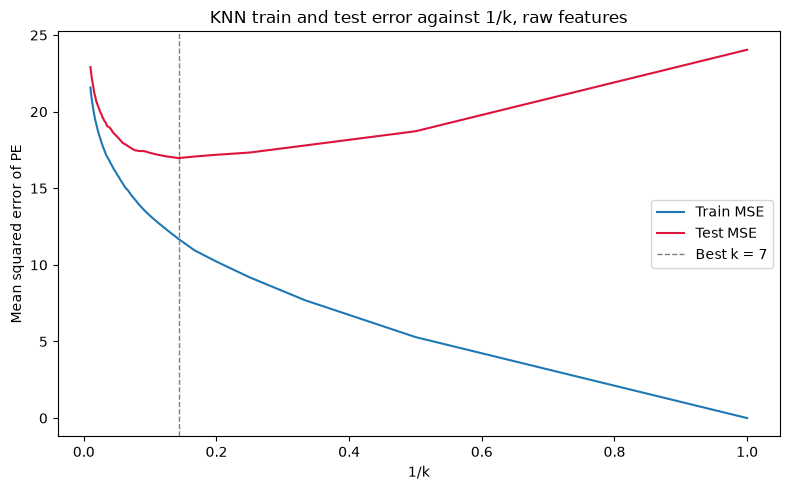

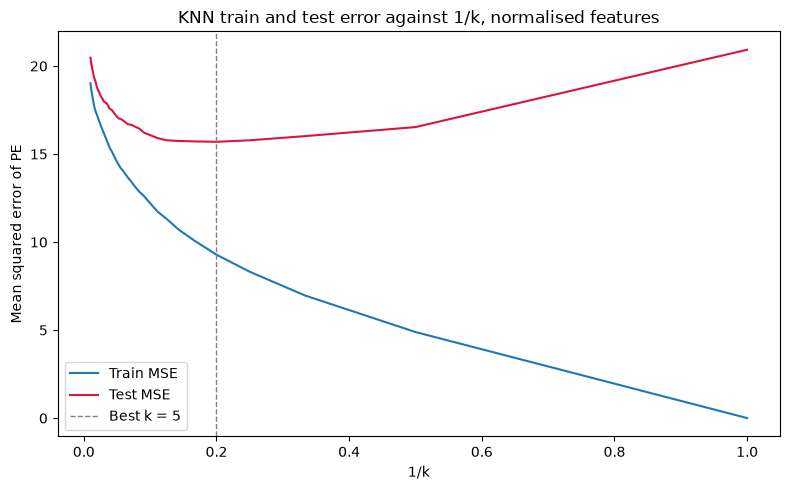

In [33]:
for name, table in sweeps.items():
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(1 / table["k"], table["Train MSE"], color="tab:blue", label="Train MSE")
    ax.plot(1 / table["k"], table["Test MSE"], color="crimson", label="Test MSE")
    k, tied, lowest = best_k(table)
    ax.axvline(1 / k, color="grey", ls="--", lw=1, label=f"Best k = {k}")
    ax.set_title("KNN train and test error against 1/k, " + name + " features")
    ax.set_xlabel("1/k")
    ax.set_ylabel("Mean squared error of PE")
    ax.legend()
    fig.tight_layout()
    plt.show()

I chose two figures, one for raw features and one for normalised features, with the training and the test curve on the same axes in each so that the gap between them is readable. Both plot the error against 1/k as the assignment asks, so flexibility increases from left to right.

At the left edge, where 1/k is near zero and k is near 100, the fit averages over a hundred neighbours and is almost flat. The training and test errors are both high and close together there, 19.02 in training and 20.48 in test at k = 100 on normalised features, because the model is too smooth to follow the data. As 1/k grows the model becomes more flexible and both errors fall.

The training error keeps falling all the way to the right edge, reaching exactly 0.000000000000 at k = 1. A single neighbour can give nothing else, because the nearest neighbour of a training point is the point itself, so the prediction is its own value of PE and the training error is zero.

The test curves do not follow the training error down. They bottom out at k = 5 for normalised features, with a test MSE of 15.694824, and at k = 7 for raw features, with 16.972379. Both test curves then turn back up, towards 20.92 for normalised features and 24.04 for raw features at k = 1, as the fit starts chasing single neighbours. The rise at the right-hand end, against a training error falling to zero, is the variance cost of too much flexibility.

Normalising the features fits better. The best normalised sweep reaches a test MSE of 15.694824 at k = 5, against 16.972379 at k = 7 for the raw sweep, an improvement of 1.277555 or 7.5 per cent.

Normalising helps because KNN measures distance across all four predictors at once, and on raw features each column contributes to that distance in proportion to its own spread rather than to the size of its numbers. The training standard deviations printed above are 7.462864 for AT, 12.758445 for V, 5.979385 for AP and 14.510456 for RH. So the raw neighbour search is led by RH and V, the two widest columns. AT counts for about half as much as RH, even though parts (c) and (d) showed it is the predictor that matters most, and AP counts for least of all, despite sitting near 1013, because it varies least.

Normalising puts all four on a common footing. The normalised test curve then sits below the raw test curve at every one of the hundred values of k, not only at the optimum, with the smallest gap between them being 0.922026 at k = 13.

### (j ) Compare KNN and Linear

In [34]:
# Part (h) model 2 is the linear model with the smallest test error, so it is the one
# the assignment asks to compare against.
knn_k, knn_tied, knn_test_mse = best_k(sweeps["normalised"])
knn_train_mse = float(
    sweeps["normalised"].loc[sweeps["normalised"]["k"] == knn_k, "Train MSE"].iloc[0])
linear_train_mse = mse(train["PE"], pred2_train)
linear_test_mse = mse(test["PE"], pred2_test)

comparison = pd.DataFrame({
    "Model": ["KNN, normalised features, k = %d" % knn_k,
              "Linear, part (h) model 2, 11 terms"],
    "Train MSE": [knn_train_mse, linear_train_mse],
    "Test MSE": [knn_test_mse, linear_test_mse],
})
comparison["Test minus train"] = comparison["Test MSE"] - comparison["Train MSE"]
comparison

,Model,Train MSE,Test MSE,Test minus train
0,"KNN, normalised features, k = 5",9.281531,15.694824,6.413293
1,"Linear, part (h) model 2, 11 terms",17.854503,18.744278,0.889775


In [35]:
print("KNN improvement in test MSE: %.6f" % (linear_test_mse - knn_test_mse))
print("as a share of the linear test MSE: %.1f%%"
      % (100 * (linear_test_mse - knn_test_mse) / linear_test_mse))
print("raw-feature KNN at k = %d for reference: %.6f"
      % best_k(sweeps["raw"])[::2])

KNN improvement in test MSE: 3.049454
as a share of the linear test MSE: 16.3%
raw-feature KNN at k = 7 for reference: 16.972379


KNN predicts better on the held-out data. With normalised features and k = 5 its test MSE is 15.694824, against 18.744278 for part (h) model 2, the linear model with the smallest test error. KNN's advantage over model 2 is 3.049454 of test MSE, or 16.3 per cent. Even the raw-feature sweep beats model 2, at a test MSE of 16.972379. The comparison is fair because KNN and model 2 were trained on the same 6698 rows and scored on the same 2870 rows, rebuilt from seed 42.

The reason KNN wins is visible in what parts (f) and (g) already found. Part (f) showed that every predictor carries curvature, with the quadratic and cubic terms significant and R squared rising by 0.0288 for AP, 0.0185 for V and 0.0129 for AT. Part (g) showed that four of the six pairwise interactions are significant, the AT and V term strongest at t = 23.3.

A linear model can only use structure that has been written into it by hand. Model 2 gets eleven terms, chosen by p value, so it captures the curvature and interaction that someone thought to include and nothing else. KNN is told none of this and still captures that structure, because averaging the five nearest neighbours follows however PE actually varies with the four predictors close to each test point, whatever curvature or interaction is present, without anyone naming the terms. Picking up that structure unaided is what saves KNN the 3.049454 of test MSE.

Each approach gives up something the other keeps. A linear model returns interpretable coefficients with standard errors and p values. The part (d) fit says that a degree of AT costs 1.978 MW with the others held fixed, and the same coefficients carry the hypothesis tests of parts (d), (f) and (g). KNN returns none of that, only predictions. KNN also has no compact fitted form, so the whole 6698-row training set must be kept and searched for every new prediction, whereas model 2 needs only eleven numbers.

Model 2 and KNN also differ in their train-test gaps. Model 2 moves from 17.854503 to 18.744278, a gap of 0.889775, while KNN at k = 5 moves from 9.281531 to 15.694824, a gap of 6.413293. So KNN's training error is a much poorer guide to how it will perform on new hours.

If the purpose is prediction, KNN wins here. If the purpose is to explain how ambient conditions drive output, the linear model is the one that answers the question.

## 2. ISLR: 2.4.1

### (a) The sample size n is extremely large, and the number of predictors p is small.

Better. A flexible method has lower bias, because it can approximate a wider range of true functions. It pays for that with higher variance, since it can follow noise in the particular sample it was trained on. Variance falls as the sample size grows, so with n extremely large and p small the variance penalty is small and the bias reduction dominates. An inflexible method, by contrast, would be stuck with whatever bias its restrictive form imposes.

### (b) The number of predictors p is extremely large, and the number of observations n is small.

Worse. Here the variance side of the trade-off dominates. With p extremely large and n small, there are few observations relative to the number of parameters the method must estimate. A flexible method therefore has very little data per parameter, and it will fit the noise in the sample rather than the signal, which gives high variance and poor performance on new data. An inflexible method accepts some bias in exchange for a fit that is stable across samples, and in this setting that is the better bargain.

### (c) The relationship between the predictors and response is highly non-linear.

Better. When the true relationship is highly non-linear, an inflexible method such as linear regression carries large bias that no amount of data will remove, because the shape it can represent does not include the truth. A flexible method can bend to follow the true shape, and so it cuts the bias sharply. It does cost more variance, but against a badly mis-specified inflexible alternative the bias reduction is much the larger effect.

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

Worse. The error variance cannot be reduced by any method, so it is not what separates a flexible method from an inflexible one. What matters is that with very noisy observations a flexible method cannot tell signal from noise, and it will bend to follow the noise, which inflates its variance badly. An inflexible method is too rigid to chase that noise, so its variance stays low, and its bias is the smaller price in this setting. The inflexible method therefore wins when the error variance is extremely high.

## 3. ISLR: 2.4.7

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

In [36]:
observations = pd.DataFrame({
    "X1": [0, 2, 0, 0, -1, 1],
    "X2": [3, 0, 1, 1, 0, 1],
    "X3": [0, 0, 3, 2, 1, 1],
    "Y": ["Red", "Red", "Red", "Green", "Green", "Red"],
}, index=range(1, 7))
observations.index.name = "Obs"

test_point = np.array([0, 0, 0])
squared = ((observations[["X1", "X2", "X3"]].to_numpy() - test_point) ** 2).sum(axis=1)

def surd(value):
    """The exact distance: an integer where the square is perfect, a surd otherwise."""
    root = int(round(value ** 0.5))
    return str(root) if root * root == value else f"sqrt({value})"

distances = observations.copy()
distances["Squared distance"] = squared
distances["Exact distance"] = [surd(int(v)) for v in squared]
distances["Distance"] = np.sqrt(squared)
distances

,X1,X2,X3,Y,Squared distance,Exact distance,Distance
Obs,,,,,,,
1,0,3,0,Red,9,3,3.000000
2,2,0,0,Red,4,2,2.000000
3,0,1,3,Red,10,sqrt(10),3.162278
4,0,1,2,Green,5,sqrt(5),2.236068
5,-1,0,1,Green,2,sqrt(2),1.414214
6,1,1,1,Red,3,sqrt(3),1.732051


In [37]:
ranked = distances.sort_values("Distance")
print("observations in order of distance from the test point:")
for rank, (obs, row) in enumerate(ranked.iterrows(), start=1):
    print(f"  {rank}. observation {obs}: {row['Exact distance']:>8s} "
          f"= {row['Distance']:.4f}, class {row['Y']}")

observations in order of distance from the test point:
  1. observation 5:  sqrt(2) = 1.4142, class Green
  2. observation 6:  sqrt(3) = 1.7321, class Red
  3. observation 2:        2 = 2.0000, class Red
  4. observation 4:  sqrt(5) = 2.2361, class Green
  5. observation 1:        3 = 3.0000, class Red
  6. observation 3: sqrt(10) = 3.1623, class Red


The test point is the origin, so each Euclidean distance is the square root of X1 squared plus X2 squared plus X3 squared. The six distances are 3 for observation 1, 2 for observation 2, sqrt(10) for observation 3, sqrt(5) for observation 4, sqrt(2) for observation 5 and sqrt(3) for observation 6. To four decimal places those are 3.0000, 2.0000, 3.1623, 2.2361, 1.4142 and 1.7321. Two of them are whole numbers, and the other four are square roots that do not simplify.

### (b) What is our prediction with K = 1? Why?

Green. The response here is a class label rather than a number, so KNN predicts by taking the classes of the K nearest neighbours and choosing the most common one. With K = 1 there is only one neighbour to consult, so that neighbour decides the answer on its own. The nearest observation to the origin is observation 5, at distance sqrt(2), which is 1.4142. The next nearest is observation 6, at sqrt(3) or 1.7321, so no other observation is closer. Observation 5 is Green, so the prediction is Green.

### (c) What is our prediction with K = 3? Why?

Red. With K = 3 the three nearest observations are, in order of distance, observation 5 at sqrt(2) = 1.4142, which is Green, observation 6 at sqrt(3) = 1.7321, which is Red, and observation 2 at 2, which is Red. The prediction is the majority class among those three labels rather than any kind of average. The vote is two Red against one Green, so the majority is Red. Note that the nearest single neighbour is still Green. Widening the neighbourhood from one to three is what changes the answer.

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

Small. K controls how flexible the fitted decision boundary is. A small K bases each prediction on a tiny neighbourhood, so the fitted boundary is free to change direction from one small region to the next and can bend sharply to follow a true boundary that is highly non-linear. A large K averages the vote over a wide neighbourhood, which smooths the fitted boundary out into something close to linear and leaves it unable to trace the sharp turns of the true boundary, whatever the sample size.

So when the Bayes decision boundary is highly non-linear, the best K is small, because only a small K is flexible enough to match its shape. The extra variance that a small K brings is the price paid for that flexibility, not the reason for choosing it.